# Avaliar e melhorar os modelos (Módulo 7)
Aqui vemos quão bons são os modelos e se conseguimos melhorá-los.

| Secção | O que vemos |
|---|---|
| 1. Preparação | Os dados e os modelos |
| 2. Matriz de confusão | Onde o modelo acerta e onde erra |
| 3. Precision, Recall e F1 | Notas de desempenho |
| 4. Curva ROC e AUC | Quão bem o modelo separa as classes |
| 5. Overfitting e underfitting | Se o modelo decorou ou aprendeu pouco |
| 6. Ajustar o modelo | Tentar melhorar os modelos |
| 7. Escolher o modelo | Qual usar no fim |
| 8. Conclusões | Resumo |

**Como avaliamos:** usamos validação cruzada no treino (cada amostra é prevista por um modelo que não a viu). O teste só é usado no fim, uma vez.

**Classes:** a classe "positiva" é `malicious`. A classe mais pequena é `non-malicious`.

Correr o comando: `!pip install -q xgboost`.

## 1. Preparação
Carregamos os dados e dividimos em treino e teste.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_predict, cross_val_score,
                                     learning_curve, validation_curve, GridSearchCV, RandomizedSearchCV)
from sklearn.metrics import (make_scorer, f1_score, recall_score, precision_score, accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

df = pd.read_csv('../../data/raw/uci_malware_detection.csv').drop_duplicates().reset_index(drop=True)
feat_cols = [c for c in df.columns if c != 'Label' and df[c].nunique() > 1]
X = df[feat_cols]
y = (df['Label'] == 'malicious').astype(int)          # 1 = malicious, 0 = non-malicious

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print('Treino:', y_train.value_counts().to_dict(), '| Teste:', y_test.value_counts().to_dict())

Treino: (296, 503) | Teste: (75, 503)
Treino: {1: 240, 0: 56} | Teste: {1: 61, 0: 14}


### 1.1 Passos de preparação das características
São os mesmos do notebook anterior: escolher características e criar as novas.

In [2]:
class SelecionarFeatures(BaseEstimator, TransformerMixin):
    """Remove features quase constantes e colunas duplicadas (ajustado só no treino)."""
    def __init__(self, min_freq=0.01):
        self.min_freq = min_freq
    def fit(self, X, y=None):
        freq = X.mean()
        keep = freq[(freq >= self.min_freq) & (freq <= 1 - self.min_freq)].index
        self.cols_ = list(keep[~X[keep].T.duplicated().values])
        return self
    def transform(self, X):
        return X[self.cols_]

class AdicionarFeatures(BaseEstimator, TransformerMixin):
    """Cria n_ativas, n_raras_ativas, n_comuns_ativas e prop_raras (sem usar o alvo)."""
    def __init__(self, limite_rara=0.05, limite_comum=0.5):
        self.limite_rara = limite_rara
        self.limite_comum = limite_comum
    def fit(self, X, y=None):
        freq = X.mean()
        self.raras_ = list(freq[freq < self.limite_rara].index)
        self.comuns_ = list(freq[freq >= self.limite_comum].index)
        return self
    def transform(self, X):
        out = X.copy()
        n = X.sum(axis=1)
        raras = X[self.raras_].sum(axis=1)
        out['n_ativas'] = n
        out['n_raras_ativas'] = raras
        out['n_comuns_ativas'] = X[self.comuns_].sum(axis=1)
        out['prop_raras'] = (raras / n.replace(0, np.nan)).fillna(0)
        return out

def montar(est, escala):
    passos = [('sel', SelecionarFeatures()), ('fe', AdicionarFeatures())]
    if escala:
        passos.append(('scaler', StandardScaler()))
    passos.append(('clf', est))
    return Pipeline(passos)

### 1.2 Modelos que vamos comparar
Escolhemos modelos de tipos diferentes: Regressão Logística, Gaussian NB, SVM, Random Forest, XGBoost e kNN (o mais fraco, serve de comparação).

In [3]:
n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()

# nome: (estimador, precisa de scaler?)
base = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE), True),
    'Gaussian NB':         (GaussianNB(), False),
    'SVM (RBF)':           (SVC(kernel='rbf', class_weight='balanced', random_state=RANDOM_STATE), True),
    'Random Forest':       (RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1), False),
    'XGBoost':             (XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, eval_metric='logloss',
                                          scale_pos_weight=n_neg / n_pos, random_state=RANDOM_STATE, n_jobs=-1), False),
    'kNN (k=5)':           (KNeighborsClassifier(n_neighbors=5), True),
}
pipes = {nome: montar(clone(est), esc) for nome, (est, esc) in base.items()}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
f1_min = make_scorer(f1_score, pos_label=0)
print('Modelos:', list(pipes))

Modelos: ['Logistic Regression', 'Gaussian NB', 'SVM (RBF)', 'Random Forest', 'XGBoost', 'kNN (k=5)']


### 1.3 Previsões "justas"
Para cada amostra do treino, o modelo faz a previsão sem a ter visto durante o treino. Assim avaliamos com todas as amostras de treino, e não só com as poucas do teste.

In [4]:
def pontuacoes(pipe, Xa, ya, cv):
    """Score contínuo da classe positiva (malicious): predict_proba se existir, senão decision_function."""
    if hasattr(pipe.named_steps['clf'], 'predict_proba'):
        return cross_val_predict(pipe, Xa, ya, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    return cross_val_predict(pipe, Xa, ya, cv=cv, method='decision_function', n_jobs=-1)

oof_pred, oof_score = {}, {}
for nome, pipe in pipes.items():
    oof_pred[nome] = cross_val_predict(pipe, X_train, y_train, cv=skf, n_jobs=-1)
    oof_score[nome] = pontuacoes(pipe, X_train, y_train, skf)
print('Previsões fora do fold calculadas para', len(oof_pred), 'modelos')

Previsões fora do fold calculadas para 6 modelos


## 2. Matriz de confusão
É uma tabela que mostra os acertos e os erros do modelo:

| | Previu `non-malicious` | Previu `malicious` |
|---|---|---|
| **Era `non-malicious`** | Acertou | Falso alarme (disse malware, mas não era) |
| **Era `malicious`** | **Malware que passou** | Acertou |

Em segurança, o erro mais grave é deixar passar malware. Um falso alarme é chato, mas menos perigoso.

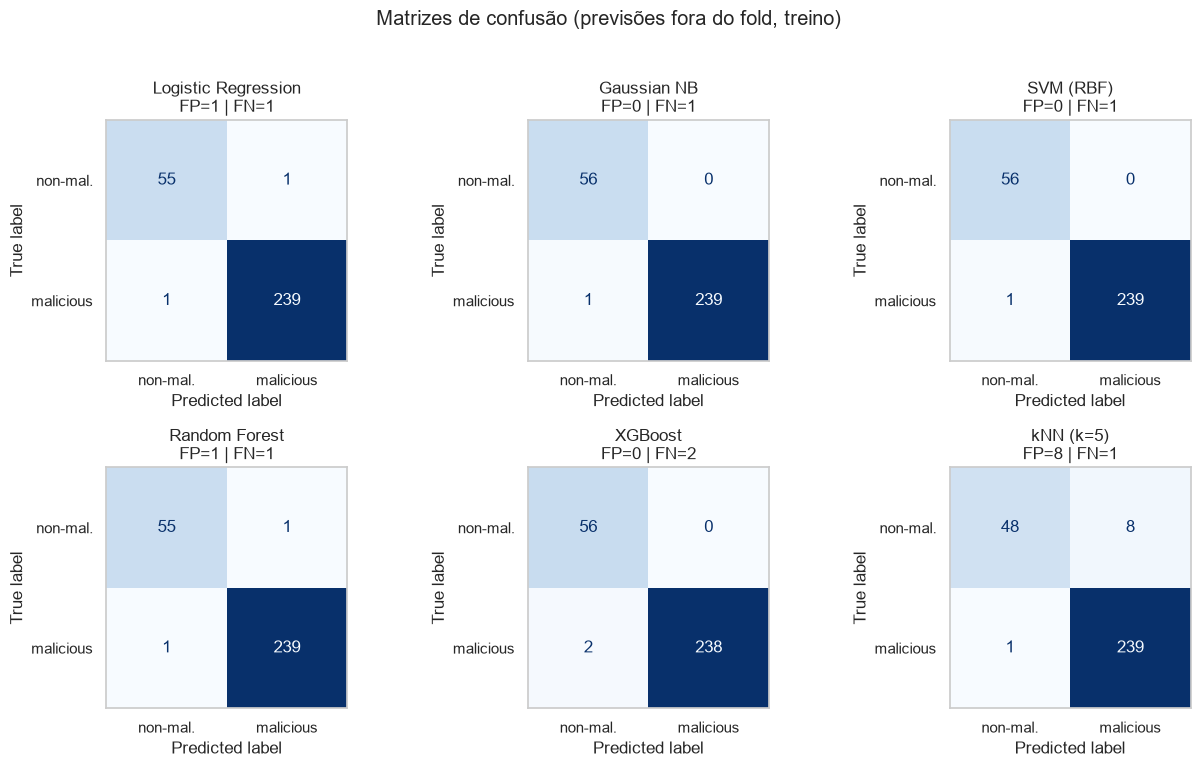

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, (nome, pred) in zip(axes.ravel(), oof_pred.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_train, pred, display_labels=['non-mal.', 'malicious'], cmap='Blues', colorbar=False, ax=ax)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    ax.set_title(f'{nome}\nFP={fp} | FN={fn}')
    ax.grid(False)
plt.suptitle('Matrizes de confusão (previsões fora do fold, treino)', y=1.02)
plt.tight_layout(); plt.show()

In [6]:
linhas = []
for nome, pred in oof_pred.items():
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    linhas.append({'modelo': nome, 'VN': tn, 'FP': fp, 'FN': fn, 'VP': tp})
display(pd.DataFrame(linhas).set_index('modelo'))

,VN,FP,FN,VP
modelo,,,,
Logistic Regression,55,1,1,239
Gaussian NB,56,0,1,239
SVM (RBF),56,0,1,239
Random Forest,55,1,1,239
XGBoost,56,0,2,238
kNN (k=5),48,8,1,239


## 3. Precision, Recall e F1
- **Precision:** das vezes que o modelo disse "é desta classe", quantas estava certo.
- **Recall:** de todos os exemplos reais da classe, quantos o modelo encontrou.
- **F1:** uma nota única que junta as duas.

Calculamos para cada classe. Damos mais atenção ao F1 e ao recall da classe pequena, porque a percentagem total de acertos engana (dizer sempre "malicious" já dá 81%).

In [7]:
linhas = []
for nome, pred in oof_pred.items():
    linhas.append({
        'modelo': nome,
        'Accuracy': accuracy_score(y_train, pred),
        'Balanced acc.': balanced_accuracy_score(y_train, pred),
        'Precision (non-mal.)': precision_score(y_train, pred, pos_label=0, zero_division=0),
        'Recall (non-mal.)': recall_score(y_train, pred, pos_label=0),
        'F1 (non-mal.)': f1_score(y_train, pred, pos_label=0),
        'Precision (malicious)': precision_score(y_train, pred, pos_label=1),
        'Recall (malicious)': recall_score(y_train, pred, pos_label=1),
        'F1 (malicious)': f1_score(y_train, pred, pos_label=1),
    })
metricas = pd.DataFrame(linhas).set_index('modelo').sort_values('F1 (non-mal.)', ascending=False)
display(metricas.round(3))
print('Referência: prever sempre "malicious" daria accuracy =', round(y_train.mean(), 3), '(e F1 = 0 na classe minoritária)')

,Accuracy,Balanced acc.,Precision (non-mal.),Recall (non-mal.),F1 (non-mal.),Precision (malicious),Recall (malicious),F1 (malicious)
modelo,,,,,,,,
Gaussian NB,0.997,0.998,0.982,1.000,0.991,1.000,0.996,0.998
SVM (RBF),0.997,0.998,0.982,1.000,0.991,1.000,0.996,0.998
XGBoost,0.993,0.996,0.966,1.000,0.982,1.000,0.992,0.996
Logistic Regression,0.993,0.989,0.982,0.982,0.982,0.996,0.996,0.996
Random Forest,0.993,0.989,0.982,0.982,0.982,0.996,0.996,0.996
kNN (k=5),0.970,0.926,0.980,0.857,0.914,0.968,0.996,0.982


Referência: prever sempre "malicious" daria accuracy = 0.811 (e F1 = 0 na classe minoritária)


In [8]:
melhor_nome = metricas.index[0]
print('Relatório completo para', melhor_nome, '(previsões fora do fold):')
print(classification_report(y_train, oof_pred[melhor_nome], target_names=['non-malicious', 'malicious']))

Relatório completo para Gaussian NB (previsões fora do fold):
               precision    recall  f1-score   support

non-malicious       0.98      1.00      0.99        56
    malicious       1.00      1.00      1.00       240

     accuracy                           1.00       296
    macro avg       0.99      1.00      0.99       296
 weighted avg       1.00      1.00      1.00       296



## 4. Curva ROC e AUC
A curva ROC mostra quão bem o modelo separa as duas classes. A **AUC** resume a curva num número: 0,5 é como atirar uma moeda ao ar e 1 é separação perfeita.

Mostramos também a curva Precision-Recall, que é mais útil quando uma classe é muito mais pequena.

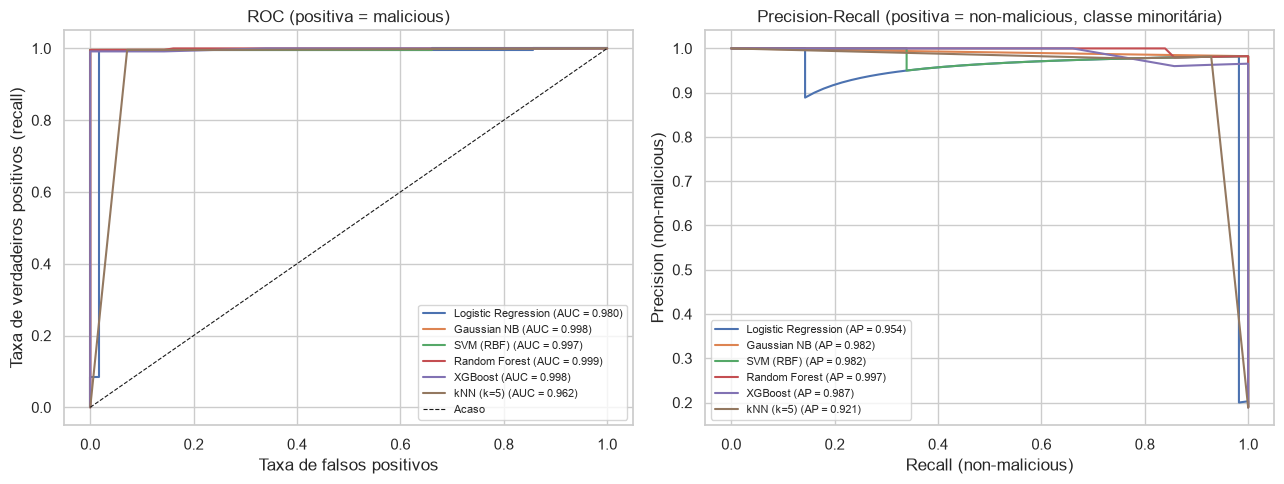

,AUC-ROC
Random Forest,0.9994
XGBoost,0.9980
Gaussian NB,0.9979
SVM (RBF),0.9972
Logistic Regression,0.9801
kNN (k=5),0.9619


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nome, sc in oof_score.items():
    fpr, tpr, _ = roc_curve(y_train, sc)
    axes[0].plot(fpr, tpr, label=f'{nome} (AUC = {roc_auc_score(y_train, sc):.3f})')
    # classe minoritária como positiva: inverter o score
    p, r, _ = precision_recall_curve(1 - y_train, -sc)
    axes[1].plot(r, p, label=f'{nome} (AP = {average_precision_score(1 - y_train, -sc):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8, label='Acaso')
axes[0].set_xlabel('Taxa de falsos positivos'); axes[0].set_ylabel('Taxa de verdadeiros positivos (recall)')
axes[0].set_title('ROC (positiva = malicious)'); axes[0].legend(loc='lower right', fontsize=8)
axes[1].set_xlabel('Recall (non-malicious)'); axes[1].set_ylabel('Precision (non-malicious)')
axes[1].set_title('Precision-Recall (positiva = non-malicious, classe minoritária)'); axes[1].legend(loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()

auc = pd.Series({n: roc_auc_score(y_train, s) for n, s in oof_score.items()}).sort_values(ascending=False)
display(auc.round(4).to_frame('AUC-ROC'))

**Cuidado:** valores à volta de 0,99 ou 1 mostram que o modelo separa quase tudo. É coerente com a análise dos dados, mas não garante o mesmo resultado com malware novo.

## 5. Overfitting e underfitting
- **Overfitting:** o modelo decora os dados de treino e falha com dados novos (nota alta no treino, mais baixa na validação).
- **Underfitting:** o modelo é simples demais e falha até no treino.

### 5.1 Curvas de aprendizagem
Mostram como a nota muda à medida que damos mais amostras ao modelo.

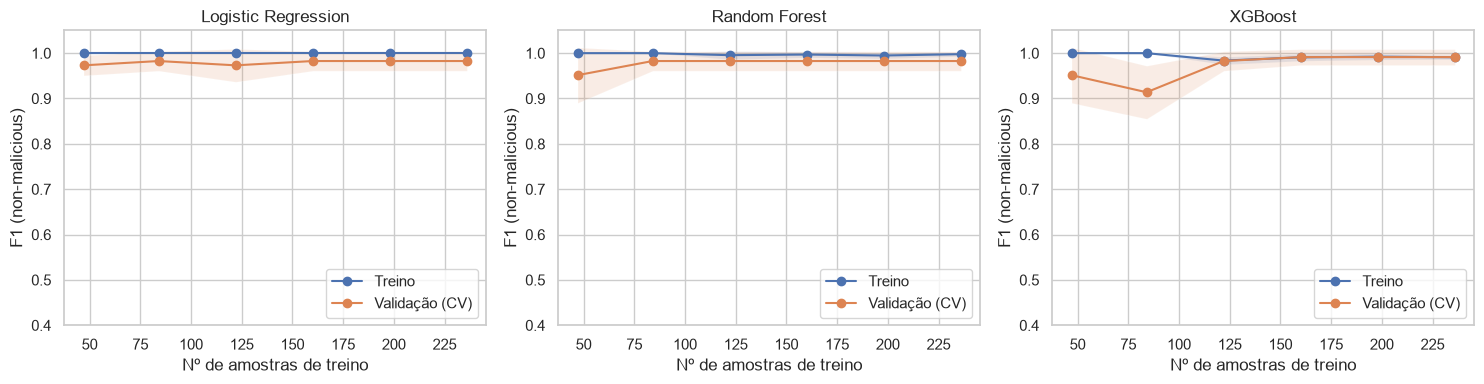

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nome in zip(axes, ['Logistic Regression', 'Random Forest', 'XGBoost']):
    tamanhos, tr, va = learning_curve(pipes[nome], X_train, y_train, cv=skf, scoring=f1_min,
                                      train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1, random_state=RANDOM_STATE)
    ax.plot(tamanhos, tr.mean(axis=1), 'o-', label='Treino')
    ax.fill_between(tamanhos, tr.mean(axis=1) - tr.std(axis=1), tr.mean(axis=1) + tr.std(axis=1), alpha=0.15)
    ax.plot(tamanhos, va.mean(axis=1), 'o-', label='Validação (CV)')
    ax.fill_between(tamanhos, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), alpha=0.15)
    ax.set_title(nome); ax.set_xlabel('Nº de amostras de treino'); ax.set_ylabel('F1 (non-malicious)')
    ax.set_ylim(0.4, 1.05); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

**Resultado:** no treino a nota é quase 1 e na validação é um pouco mais baixa (0,98 a 0,99). A diferença é pequena, por isso há pouco overfitting. A partir de cerca de 120 amostras a nota já não melhora, por isso mais dados quase não ajudariam.

### 5.2 Curvas de validação
Mudamos uma definição do modelo (um "hiperparâmetro") e vemos o efeito no treino e na validação.

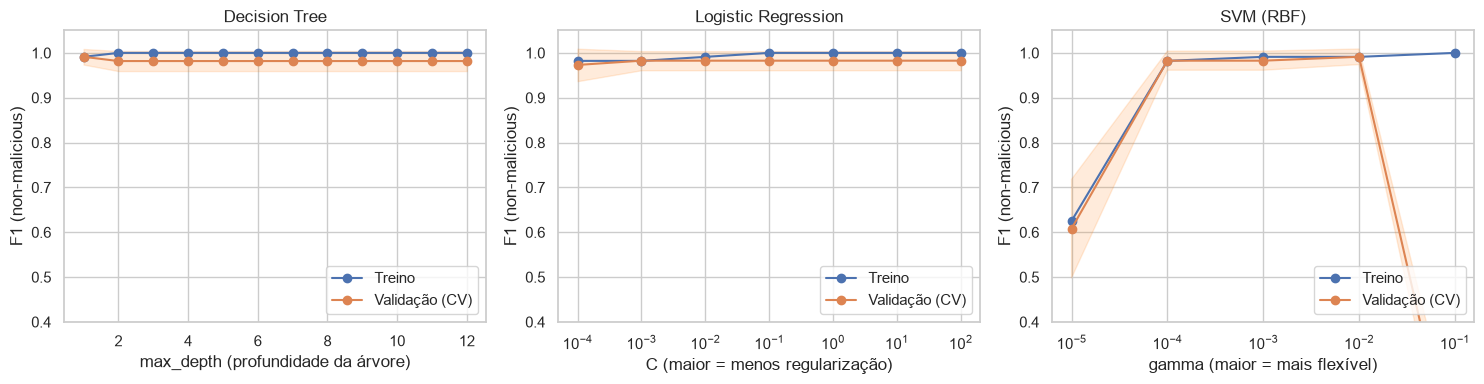

In [11]:
def curva_validacao(nome, param, valores, ax, log=False, rotulo=None):
    tr, va = validation_curve(pipes[nome], X_train, y_train, param_name=param, param_range=valores,
                              cv=skf, scoring=f1_min, n_jobs=-1)
    xs = valores
    plot = ax.semilogx if log else ax.plot
    plot(xs, tr.mean(axis=1), 'o-', label='Treino')
    plot(xs, va.mean(axis=1), 'o-', label='Validação (CV)')
    ax.fill_between(xs, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), alpha=0.15, color='tab:orange')
    ax.set_title(nome.lstrip('_')); ax.set_xlabel(rotulo or param); ax.set_ylabel('F1 (non-malicious)'); ax.set_ylim(0.4, 1.05); ax.legend(loc='lower right')

dt_pipe_base = montar(DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE), False)
pipes['_Decision Tree'] = dt_pipe_base       # só para esta curva

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
curva_validacao('_Decision Tree', 'clf__max_depth', list(range(1, 13)), axes[0], rotulo='max_depth (profundidade da árvore)')
curva_validacao('Logistic Regression', 'clf__C', np.logspace(-4, 2, 7), axes[1], log=True, rotulo='C (maior = menos regularização)')
curva_validacao('SVM (RBF)', 'clf__gamma', np.logspace(-5, -1, 5), axes[2], log=True, rotulo='gamma (maior = mais flexível)')
plt.tight_layout(); plt.show()
del pipes['_Decision Tree']

**Resultado:**
- **Árvore de decisão:** mesmo muito simples já dá um bom resultado, porque basta uma característica para separar quase tudo.
- **Regressão Logística:** a definição `C` quase não faz diferença.
- **SVM:** é o único em que a definição importa. Com `gamma` muito pequeno aprende pouco (underfitting). Com `gamma` muito grande decora o treino e falha na validação (overfitting). A zona boa fica no meio.

## 6. Ajustar as definições do modelo
Cada modelo tem "botões" (hiperparâmetros) que podemos afinar. Experimentamos várias combinações e ficamos com a melhor, medida por validação cruzada só no treino. Fazemos isto no SVM, no Random Forest e no XGBoost.

In [12]:
pesquisas = {
    'SVM (RBF)': GridSearchCV(
        pipes['SVM (RBF)'],
        {'clf__C': [0.1, 1, 10, 100], 'clf__gamma': [1e-4, 1e-3, 1e-2, 'scale']},
        scoring=f1_min, cv=skf, n_jobs=-1),
    'Random Forest': RandomizedSearchCV(
        pipes['Random Forest'],
        {'clf__n_estimators': [100, 200, 400], 'clf__max_depth': [None, 5, 10, 20],
         'clf__min_samples_leaf': [1, 2, 4], 'clf__max_features': ['sqrt', 'log2', 0.2]},
        n_iter=15, scoring=f1_min, cv=skf, n_jobs=-1, random_state=RANDOM_STATE),
    'XGBoost': RandomizedSearchCV(
        pipes['XGBoost'],
        {'clf__n_estimators': [100, 200, 400], 'clf__max_depth': [2, 3, 4, 6], 'clf__learning_rate': [0.03, 0.1, 0.3],
         'clf__subsample': [0.7, 1.0], 'clf__colsample_bytree': [0.5, 1.0]},
        n_iter=15, scoring=f1_min, cv=skf, n_jobs=-1, random_state=RANDOM_STATE),
}

for nome, busca in pesquisas.items():
    busca.fit(X_train, y_train)
    print(f'{nome}: melhor F1 (CV) = {busca.best_score_:.3f}')
    print('   ', {k.replace('clf__', ''): v for k, v in busca.best_params_.items()})

SVM (RBF): melhor F1 (CV) = 0.991
    {'C': 0.1, 'gamma': 0.01}
Random Forest: melhor F1 (CV) = 0.991
    {'n_estimators': 400, 'min_samples_leaf': 2, 'max_features': 0.2, 'max_depth': 10}
XGBoost: melhor F1 (CV) = 0.991
    {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.3, 'colsample_bytree': 0.5}


### 6.1 Antes e depois
Comparamos o modelo com as definições normais e depois de afinado.

In [13]:
linhas = []
for nome, busca in pesquisas.items():
    antes = cross_val_score(pipes[nome], X_train, y_train, cv=skf, scoring=f1_min)
    linhas.append({'modelo': nome, 'F1 antes (default)': antes.mean(), 'F1 depois (tuning)': busca.best_score_,
                   'ganho': busca.best_score_ - antes.mean()})
comp = pd.DataFrame(linhas).set_index('modelo')
display(comp.round(3))

,F1 antes (default),F1 depois (tuning),ganho
modelo,,,
SVM (RBF),0.991,0.991,0.000
Random Forest,0.983,0.991,0.009
XGBoost,0.983,0.991,0.008


**Cuidado:** a melhor nota entre muitas tentativas costuma ser otimista (parte pode ser sorte). Por isso repetimos o processo de forma mais exigente ("validação aninhada"): o ajuste é refeito dentro de cada parte, e as amostras de fora ficam sempre de parte.

In [15]:
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)     # folds externos diferentes dos internos
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

aninhado = {}
for nome, busca in pesquisas.items():
    interna = clone(busca).set_params(cv=inner)
    s = cross_val_score(interna, X_train, y_train, cv=outer, scoring=f1_min)
    aninhado[nome] = s
    print(f'{nome}: F1 aninhado = {s.mean():.3f} (± {s.std():.3f})')
comp['F1 aninhado'] = pd.Series({n: s.mean() for n, s in aninhado.items()})
display(comp.round(3))

SVM (RBF): F1 aninhado = nan (± nan)
Random Forest: F1 aninhado = 0.991 (± 0.017)
XGBoost: F1 aninhado = 0.983 (± 0.021)


,F1 antes (default),F1 depois (tuning),ganho,F1 aninhado
modelo,,,,
SVM (RBF),0.991,0.991,0.000,NaN
Random Forest,0.983,0.991,0.009,0.991
XGBoost,0.983,0.991,0.008,0.983


## 7. Escolher o modelo
Regras simples:
1. Comparar pela validação cruzada (nunca pelo teste).
2. Se a diferença for muito pequena, escolher o modelo mais simples.
3. Só depois usar o teste, uma única vez.

In [ ]:
ordem_complexidade = {'Logistic Regression': 1, 'Gaussian NB': 1, 'SVM (RBF)': 2, 'Random Forest': 3, 'XGBoost': 3, 'kNN (k=5)': 2}

# tabela resumo: CV com hiperparâmetros por defeito para todos; aninhado onde houve tuning
resumo = pd.DataFrame({
    'F1 CV (default)': {n: cross_val_score(p, X_train, y_train, cv=skf, scoring=f1_min).mean() for n, p in pipes.items()},
    'AUC-ROC': auc,
})
resumo['F1 CV aninhado (tuned)'] = pd.Series({n: s.mean() for n, s in aninhado.items()})
resumo['complexidade'] = pd.Series(ordem_complexidade)
resumo['F1 de comparação'] = resumo['F1 CV aninhado (tuned)'].fillna(resumo['F1 CV (default)'])
resumo = resumo.sort_values(['F1 de comparação', 'complexidade'], ascending=[False, True])
display(resumo.round(3))

print(aninhado['SVM (RBF)'])

cross_val_score(clone(pesquisas['SVM (RBF)']).set_params(cv=inner),
                X_train, y_train, cv=outer, scoring=f1_min, error_score='raise')

,F1 CV (default),AUC-ROC,F1 CV aninhado (tuned),complexidade,F1 de comparação
Gaussian NB,0.991,0.998,NaN,1,0.991
SVM (RBF),0.991,0.997,NaN,2,0.991
Random Forest,0.983,0.999,0.991,3,0.991
Logistic Regression,0.983,0.980,NaN,1,0.983
XGBoost,0.983,0.998,0.983,3,0.983
kNN (k=5),0.913,0.962,NaN,2,0.913


In [17]:
# Escolha: maior F1 (arredondado a 2 casas, para tratar diferenças mínimas como empate) e, em caso de empate, o mais simples
resumo['_f1_arred'] = resumo['F1 de comparação'].round(2)
escolhido = resumo.sort_values(['_f1_arred', 'complexidade'], ascending=[False, True]).index[0]
print('Modelo escolhido:', escolhido)

if escolhido in pesquisas:
    modelo_final = pesquisas[escolhido].best_estimator_          # já reajustado ao treino completo
    print('Hiperparâmetros:', {k.replace('clf__', ''): v for k, v in pesquisas[escolhido].best_params_.items()})
else:
    modelo_final = clone(pipes[escolhido]).fit(X_train, y_train)

Modelo escolhido: Gaussian NB


### 7.1 Teste final
É a primeira e única vez que usamos os dados de teste.

               precision    recall  f1-score   support

non-malicious       1.00      1.00      1.00        14
    malicious       1.00      1.00      1.00        61

     accuracy                           1.00        75
    macro avg       1.00      1.00      1.00        75
 weighted avg       1.00      1.00      1.00        75

AUC-ROC no teste: 1.0


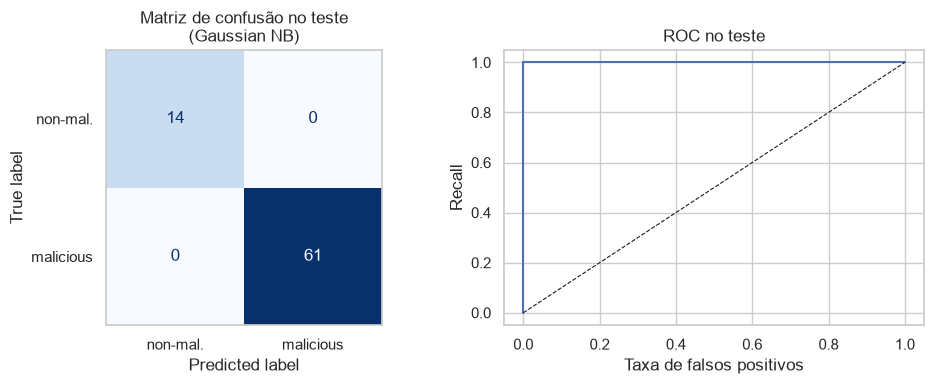

In [18]:
y_pred = modelo_final.predict(X_test)
clf = modelo_final.named_steps['clf']
score_te = modelo_final.predict_proba(X_test)[:, 1] if hasattr(clf, 'predict_proba') else modelo_final.decision_function(X_test)

print(classification_report(y_test, y_pred, target_names=['non-malicious', 'malicious']))
print('AUC-ROC no teste:', round(roc_auc_score(y_test, score_te), 4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['non-mal.', 'malicious'], cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title(f'Matriz de confusão no teste\n({escolhido})'); axes[0].grid(False)
fpr, tpr, _ = roc_curve(y_test, score_te)
axes[1].plot(fpr, tpr); axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[1].set_xlabel('Taxa de falsos positivos'); axes[1].set_ylabel('Recall'); axes[1].set_title('ROC no teste')
plt.tight_layout(); plt.show()

### 7.2 Quão fiável é o resultado do teste?
O teste tem poucas amostras (só 14 da classe pequena). Um resultado de 100% com tão poucos exemplos pode ser sorte. Por isso calculamos um intervalo: a margem onde o valor real provavelmente está.

In [ ]:
def ic_wilson(acertos, total):
    r = stats.binomtest(int(acertos), int(total)).proportion_ci(confidence_level=0.95, method='wilson')
    return r.low, r.high

for classe, nome_c in [(0, 'non-malicious'), (1, 'malicious')]:
    total = (y_test == classe).sum()
    acertos = ((y_pred == classe) & (y_test == classe)).sum()
    lo, hi = ic_wilson(acertos, total)
    print(f'Recall {nome_c}: {acertos}/{total} = {acertos/total:.3f}  | IC 95%: [{lo:.3f}, {hi:.3f}]')

Recall non-malicious: 14/14 = 1.000  | IC 95%: [0.785, 1.000]
Recall malicious: 61/61 = 1.000  | IC 95%: [0.941, 1.000]


## 8. Conclusões
**Regression Metrics** (MAE, RMSE, R²...) não se aplicam: o nosso problema é de classificação (malicioso ou não), não de prever um número.

### Resultados desta execução
- **Matriz de confusão:** os melhores modelos erram só 1 ou 2 amostras em 296. O kNN é o pior.
- **F1:** Gaussian NB e SVM lideram na classe pequena, com cerca de 0,99.
- **AUC:** todas muito altas (entre cerca de 0,96 e 1).
- **Overfitting:** pequeno. Mais dados quase não ajudariam.
- **Ajuste das definições:** no Random Forest e no XGBoost melhorou um pouco, mas dentro da margem de erro. No SVM piorou na avaliação mais exigente, porque com poucas amostras a escolha das definições é instável.
- **Modelo escolhido:** Gaussian NB (empatou com outros, mas é o mais simples).
- **Teste:** 100%, mas a margem de erro é grande por haver poucas amostras de teste.
- **Limitações:** poucas amostras da classe pequena, malware muito parecido entre si e só um teste. Não garante bons resultados com malware novo.
- **Para ler:** https://mlu-explain.github.io/ (explica Precision, Recall, F1 e ROC-AUC de forma visual).